# 1. Fundamentals: Sampling, Quantization, Adjacency and Geometry

Practice for week 1: spatial sampling and gray-level quantization of a synthetic image, storage size of
images and video, distances under 4- and 8-adjacency, and rotation/scaling done with inverse mapping and
bilinear interpolation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import deque

np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 80

def make_image(n=256):
    y, x = np.mgrid[:n, :n] / n
    img = 0.25 + 0.4 * x + 0.1 * np.sin(6 * np.pi * y)
    img[(x - 0.3) ** 2 + (y - 0.35) ** 2 < 0.04] = 0.9
    img[(x > 0.55) & (x < 0.9) & (y > 0.55) & (y < 0.85)] = 0.15
    s = (y > 0.7) & (x < 0.45)
    img[s] = 0.5 + 0.3 * np.sign(np.sin(2 * np.pi * 40 * x[s]))   # fine stripes, period 6.4 px
    return img.clip(0, 1)

img = make_image()

## 1.1 Sampling

Sampling discretizes the spatial domain. Taking every k-th pixel throws away detail and, for patterns
finer than the new sampling rate, creates aliasing: the fine stripes turn into wrong, coarse stripes.
Averaging each k×k block first (a crude low-pass filter) suppresses the aliasing.

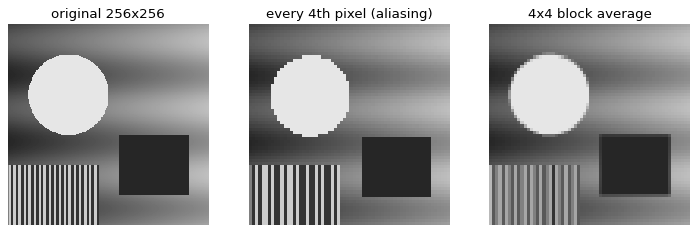

In [2]:
k = 4
naive = img[::k, ::k]
averaged = img.reshape(64, k, 64, k).mean((1, 3))
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
for a, im, t in zip(axes, [img, naive, averaged], ["original 256x256", "every 4th pixel (aliasing)", "4x4 block average"]):
    a.imshow(im, cmap="gray", vmin=0, vmax=1, interpolation="nearest"); a.set_title(t); a.axis("off")
plt.show()

## 1.2 Quantization and storage

Quantization discretizes the pixel values. With few levels the smooth ramp breaks into visible bands
(false contours). Storage is `rows × cols × bits per pixel`.

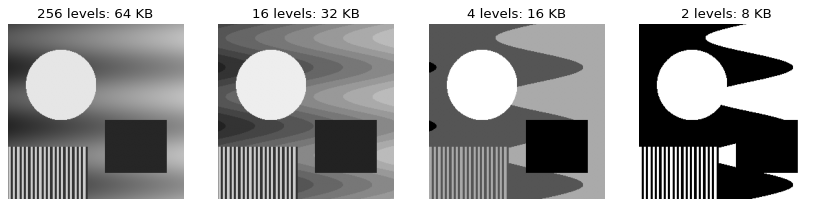

100 x 1000 image, 8 bits/pixel: 800000 bits
1 min of 1080p video, 30 fps, 24 bits/pixel: 11.2 GB uncompressed


In [3]:
def quantize(u, bits):
    L = 2 ** bits
    return np.floor(u * (L - 1) + 0.5) / (L - 1)

fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for a, b in zip(axes, [8, 4, 2, 1]):
    a.imshow(quantize(img, b), cmap="gray", vmin=0, vmax=1); a.axis("off")
    a.set_title(f"{2 ** b} levels: {256 * 256 * b / 8 / 1024:.0f} KB")
plt.show()

print("100 x 1000 image, 8 bits/pixel:", 100 * 1000 * 8, "bits")
print(f"1 min of 1080p video, 30 fps, 24 bits/pixel: {30 * 60 * 1920 * 1080 * 24 / 8 / 1e9:.1f} GB uncompressed")

## 1.3 4- and 8-adjacency

Breadth-first search over the pixel grid. With 4-neighbours the number of steps is the city-block
distance `|dx| + |dy|`; with 8-neighbours it is the chessboard distance `max(|dx|, |dy|)`.

4-adjacency == city-block: True
8-adjacency == chessboard: True
(1,1) -> (0,0): 4-adjacency 2 steps, 8-adjacency 1 step


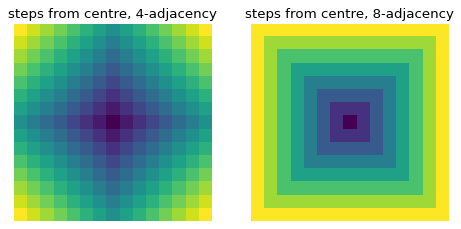

In [4]:
def bfs_steps(n, start, neigh):
    d = np.full((n, n), -1); d[start] = 0; q = deque([start])
    while q:
        y, x = q.popleft()
        for dy, dx in neigh:
            v = (y + dy, x + dx)
            if 0 <= v[0] < n and 0 <= v[1] < n and d[v] < 0:
                d[v] = d[y, x] + 1; q.append(v)
    return d

N4 = [(0, 1), (1, 0), (0, -1), (-1, 0)]
N8 = N4 + [(1, 1), (1, -1), (-1, 1), (-1, -1)]
d4, d8 = bfs_steps(15, (7, 7), N4), bfs_steps(15, (7, 7), N8)
yy, xx = np.mgrid[:15, :15]
print("4-adjacency == city-block:", np.array_equal(d4, abs(yy - 7) + abs(xx - 7)))
print("8-adjacency == chessboard:", np.array_equal(d8, np.maximum(abs(yy - 7), abs(xx - 7))))
print("(1,1) -> (0,0): 4-adjacency", bfs_steps(3, (1, 1), N4)[0, 0], "steps, 8-adjacency", bfs_steps(3, (1, 1), N8)[0, 0], "step")

fig, axes = plt.subplots(1, 2, figsize=(7, 3.3))
for a, d, t in zip(axes, [d4, d8], ["4-adjacency", "8-adjacency"]):
    a.imshow(d, cmap="viridis"); a.set_title(f"steps from centre, {t}"); a.axis("off")
plt.show()

## 1.4 Rotation and scaling

Geometric transforms use inverse mapping: for every output pixel, find where it came from in the input
and interpolate there (bilinear), so the output has no holes. A rotation matrix has determinant 1 (area is
kept); a scaling matrix has determinant `sx · sy`.

det(rotation) = 1.000, det(scaling) = 1.050
rotate +30 then -30, mean abs error in the centre: 0.0024 (interpolation smooths)


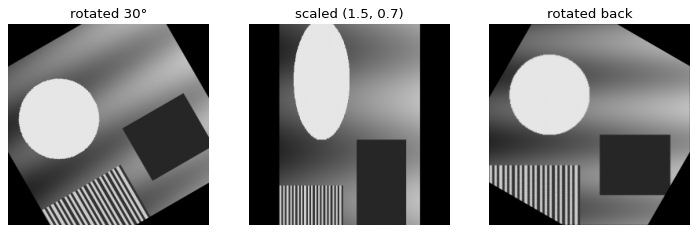

In [5]:
def warp(u, A):
    """Output pixel p takes the input value at A^-1 (p - c) + c, with bilinear interpolation."""
    n, m = u.shape
    c = np.array([[n / 2], [m / 2]])
    yy, xx = np.mgrid[:n, :m]
    y, x = np.linalg.inv(A) @ (np.stack([yy.ravel(), xx.ravel()]) - c) + c
    y0, x0 = np.floor(y).astype(int), np.floor(x).astype(int)
    dy, dx = y - y0, x - x0
    def at(yi, xi):
        ok = (yi >= 0) & (yi < n) & (xi >= 0) & (xi < m)
        return np.where(ok, u[yi.clip(0, n - 1), xi.clip(0, m - 1)], 0)
    out = (at(y0, x0) * (1 - dy) * (1 - dx) + at(y0, x0 + 1) * (1 - dy) * dx
           + at(y0 + 1, x0) * dy * (1 - dx) + at(y0 + 1, x0 + 1) * dy * dx)
    return out.reshape(n, m)

a = np.deg2rad(30)
R = np.array([[np.cos(a), -np.sin(a)], [np.sin(a), np.cos(a)]])
S = np.diag([1.5, 0.7])
print(f"det(rotation) = {np.linalg.det(R):.3f}, det(scaling) = {np.linalg.det(S):.3f}")

rot = warp(img, R)
back = warp(rot, R.T)
centre = slice(80, 176)
print(f"rotate +30 then -30, mean abs error in the centre: {np.abs(back - img)[centre, centre].mean():.4f} (interpolation smooths)")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
for ax, im, t in zip(axes, [rot, warp(img, S), back], ["rotated 30°", "scaled (1.5, 0.7)", "rotated back"]):
    ax.imshow(im, cmap="gray", vmin=0, vmax=1); ax.set_title(t); ax.axis("off")
plt.show()